In [1]:
# Hadijah Tohepaly - 202431078
# 1. Import Library

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import confusion_matrix, classification_report

In [7]:
# Hadijah Tohepaly - 202431078
# 2. Membaca Dataset

df = pd.read_csv("heart.csv")

display(df.head())

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [8]:
# Hadijah Tohepaly - 202431078
# 3. Informasi Data dan Deskripsi Statistik

df.info()

display(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


In [11]:
# Hadijah Tohepaly - 202431078
# 4. Memisahkan Fitur Numerik

fitur_kategorikal = [
    "Sex",
    "ChestPainType",
    "RestingECG",
    "ExerciseAngina",
    "ST_Slope"
]

fitur_numerik = [
    kolom for kolom in df.select_dtypes(include=np.number).columns
    if kolom != "HeartDisease"
]

print("Jumlah Fitur Numerik:", len(fitur_numerik))
print("Daftar Fitur Numerik:", fitur_numerik)

Jumlah Fitur Numerik: 6
Daftar Fitur Numerik: ['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak']


In [12]:
# Hadijah Tohepaly - 202431078
# 5. Memisahkan Fitur Kategorikal

print("Jumlah Fitur Kategorikal:", len(fitur_kategorikal))
print("Daftar Fitur Kategorikal:", fitur_kategorikal)

Jumlah Fitur Kategorikal: 5
Daftar Fitur Kategorikal: ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']


In [13]:
# Hadijah Tohepaly - 202431078
# 6. Menampilkan Nilai Unik Fitur Kategorikal

for kolom in fitur_kategorikal:
    print(kolom, ":", df[kolom].unique())

Sex : ['M' 'F']
ChestPainType : ['ATA' 'NAP' 'ASY' 'TA']
RestingECG : ['Normal' 'ST' 'LVH']
ExerciseAngina : ['N' 'Y']
ST_Slope : ['Up' 'Flat' 'Down']


In [14]:
# Hadijah Tohepaly - 202431078
# 7. Mengubah Fitur Kategorikal Menjadi Angka

df_encoded = df.copy()

le = LabelEncoder()

for kolom in fitur_kategorikal:
    df_encoded[kolom] = le.fit_transform(
        df_encoded[kolom].astype(str)
    )

display(df_encoded.head())

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,1,1,140,289,0,1,172,0,0.0,2,0
1,49,0,2,160,180,0,1,156,0,1.0,1,1
2,37,1,1,130,283,0,2,98,0,0.0,2,0
3,48,0,0,138,214,0,1,108,1,1.5,1,1
4,54,1,2,150,195,0,1,122,0,0.0,2,0


In [15]:
# Hadijah Tohepaly - 202431078
# 8. Memisahkan Fitur X dan Target Y

X = df_encoded.drop("HeartDisease", axis=1)
y = df_encoded["HeartDisease"]

print("Fitur X:")
display(X.head())

print("Target Y:")
display(y.head())

Fitur X:


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope
0,40,1,1,140,289,0,1,172,0,0.0,2
1,49,0,2,160,180,0,1,156,0,1.0,1
2,37,1,1,130,283,0,2,98,0,0.0,2
3,48,0,0,138,214,0,1,108,1,1.5,1
4,54,1,2,150,195,0,1,122,0,0.0,2


Target Y:


0    0
1    1
2    0
3    1
4    0
Name: HeartDisease, dtype: int64

In [16]:
# Hadijah Tohepaly - 202431078
# 9. Membagi Data Training dan Testing

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=0
)

print("Jumlah Data Training:", len(X_train))
print("Jumlah Data Testing:", len(X_test))

Jumlah Data Training: 688
Jumlah Data Testing: 230


In [17]:
# Hadijah Tohepaly - 202431078
# 10. Membuat dan Melatih Model Gaussian Naive Bayes

model = GaussianNB()

model.fit(X_train, y_train)

print("Model Gaussian Naive Bayes Berhasil Dilatih")

Model Gaussian Naive Bayes Berhasil Dilatih


In [18]:
# Hadijah Tohepaly - 202431078
# 11. Melakukan Prediksi Data Training dan Testing

y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)

print("Prediksi Data Training:")
print(y_pred_train)

print("\nPrediksi Data Testing:")
print(y_pred_test)

Prediksi Data Training:
[0 1 1 1 0 1 1 1 0 1 1 0 1 0 1 0 0 0 1 0 1 0 1 0 0 0 1 0 0 1 0 1 1 0 0 1 0
 0 1 0 0 0 1 1 1 0 1 0 1 1 1 1 1 0 1 0 1 0 0 1 1 0 0 0 0 1 1 1 1 1 0 0 0 1
 0 0 1 0 1 1 1 0 1 1 0 1 0 1 0 0 1 1 0 1 1 1 0 0 1 0 0 0 1 0 1 0 0 0 1 1 1
 0 0 1 0 0 0 1 1 1 0 0 0 1 1 1 1 1 1 1 1 1 1 0 1 1 1 0 1 0 0 1 1 1 1 1 1 1
 0 0 1 1 1 0 1 1 1 0 1 0 0 0 1 0 0 0 0 0 0 1 0 1 0 1 0 1 0 0 1 1 0 1 0 0 1
 1 0 1 1 1 1 0 0 0 0 1 0 0 1 1 1 0 1 1 0 1 1 0 0 0 1 1 1 0 0 0 0 1 1 0 0 0
 0 1 1 0 0 0 0 0 0 1 1 1 1 1 0 0 1 0 0 0 1 1 0 1 0 1 0 1 1 0 1 1 1 0 0 0 0
 1 1 1 1 0 0 1 0 0 0 1 1 1 0 1 1 1 1 1 0 1 1 0 1 0 0 1 1 0 1 1 1 1 1 1 1 0
 1 1 0 0 1 0 0 0 1 0 0 1 1 0 1 0 1 1 0 1 0 1 1 1 1 0 1 1 0 0 0 1 0 1 0 1 1
 1 1 1 1 1 0 1 1 0 1 0 1 0 1 0 0 0 1 0 0 0 1 1 0 1 0 1 0 1 0 1 0 1 0 1 1 1
 1 0 1 1 0 0 0 0 0 1 0 0 0 0 1 0 1 1 1 1 1 1 0 1 1 0 1 0 1 0 1 0 1 0 1 1 1
 0 0 1 1 1 0 0 0 0 0 1 1 0 1 0 1 1 1 1 1 1 1 0 1 0 1 0 0 0 1 0 0 1 0 1 1 0
 0 0 1 0 1 1 0 1 1 1 1 1 0 0 1 0 0 1 0 0 0 0 0 1 0 1 1 1 1 0 0 0 0 0 1 0 1
 

Evaluasi Training
Confusion Matrix:
[[274  44]
 [ 51 319]]

Classification Report Training:
              precision    recall  f1-score   support

           0       0.84      0.86      0.85       318
           1       0.88      0.86      0.87       370

    accuracy                           0.86       688
   macro avg       0.86      0.86      0.86       688
weighted avg       0.86      0.86      0.86       688



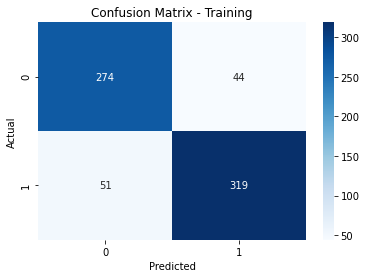

In [19]:
# Hadijah Tohepaly - 202431078
# 12. Evaluasi Training

cm_train = confusion_matrix(y_train, y_pred_train)

print("Evaluasi Training")
print("Confusion Matrix:")
print(cm_train)

print("\nClassification Report Training:")
print(classification_report(
    y_train,
    y_pred_train,
    zero_division=0
))

plt.figure(figsize=(6,4))

sns.heatmap(
    cm_train,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Confusion Matrix - Training")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

Evaluasi Testing
Confusion Matrix:
[[ 73  19]
 [ 16 122]]

Classification Report Testing:
              precision    recall  f1-score   support

           0       0.82      0.79      0.81        92
           1       0.87      0.88      0.87       138

    accuracy                           0.85       230
   macro avg       0.84      0.84      0.84       230
weighted avg       0.85      0.85      0.85       230



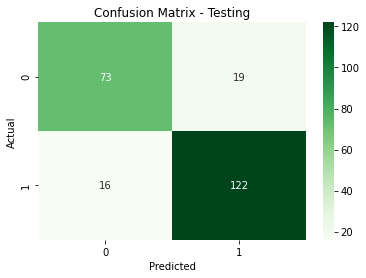

In [20]:
# Hadijah Tohepaly - 202431078
# 13. Evaluasi Testing

cm_test = confusion_matrix(y_test, y_pred_test)

print("Evaluasi Testing")
print("Confusion Matrix:")
print(cm_test)

print("\nClassification Report Testing:")
print(classification_report(
    y_test,
    y_pred_test,
    zero_division=0
))

plt.figure(figsize=(6,4))

sns.heatmap(
    cm_test,
    annot=True,
    fmt="d",
    cmap="Greens"
)

plt.title("Confusion Matrix - Testing")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [21]:
# Hadijah Tohepaly - 202431078
# 14. Pengujian dengan 1 Data Baru

data_baru = pd.DataFrame([[
    50, 1, 0, 130, 250, 0, 1,
    150, 0, 1.0, 1
]], columns=X.columns)

prediksi_baru = model.predict(data_baru)

print("Evaluasi Data Baru")
print("Hasil Prediksi:", prediksi_baru[0])

if prediksi_baru[0] == 1:
    print("Prediksi: Terindikasi Penyakit Jantung")
else:
    print("Prediksi: Tidak Terindikasi Penyakit Jantung")

Evaluasi Data Baru
Hasil Prediksi: 0
Prediksi: Tidak Terindikasi Penyakit Jantung
